# Allen–Cahn

$$
f_t = \varepsilon^2\,\Delta f + f - f^3, \qquad \varepsilon = 0.15
$$

## 1. Setup

In [1]:
import numpy as np

import nb_helpers as nb
from equivariant_pde_find.simulations import allen_cahn

EQ = "ac"
NOISE = 0.02

# ── Best configurations from the hyperparameter sweep ───────────────
#
#   "eq"  = best of  multigraph / mod_multigraph
#   "neq" = best of  pdefind / wsindy / polyjet
#
# ────────────────────────────────────────────────────────────────────
BEST = {
    (0.00, "eq"): dict(
        library="multigraph", method="weak_ibp", algorithm="stridge",
        backend="spectral", m=12, lam=1e-6, d_tol=0.1,
    ),
    (0.00, "neq"): dict(
        library="pdefind", method="weak_ibp", algorithm="stridge",
        backend="spectral", m=12, lam=1e-6, d_tol=0.1,
    ),
    (0.02, "eq"): dict(
        library="multigraph", method="weak_ibp", algorithm="rfe",
        backend="spectral", m=12, lam=0.0,
    ),
    (0.02, "neq"): dict(
        library="pdefind", method="weak_ibp", algorithm="rfe",
        backend="spectral", m=12, lam=0.0,
    ),
}

## 2. Generate the data

In [2]:
SIM = dict(N=64, L=2 * np.pi, T_end=8.0, eps=0.15, dt=0.01,
           save_every=20, seed=42)

clean, times = allen_cahn(**SIM, obs_noise=0.0)
noisy, _ = allen_cahn(**SIM, obs_noise=NOISE)

print(f'{len(clean)} snapshots over t ∈ [{times[0]:.2f}, {times[-1]:.2f}]'
      f' on a {clean.shape[1]}×{clean.shape[2]} grid')
print(f'f ∈ [{clean.min():.3f}, {clean.max():.3f}]')
nb.check_matches_dataset(clean, EQ, 'clean')
nb.check_matches_dataset(noisy, EQ, 'noise2pct')

41 snapshots over t ∈ [0.01, 8.01] on a 64×64 grid
f ∈ [-0.998, 0.995]
  vs data/ac_clean.npz: max|Δ| = 0.00e+00  → identical
  vs data/ac_noise2pct.npz: max|Δ| = 2.22e-16  → identical


2.220446049250313e-16

## 3. The motion

written: results/figures/ac_motion.pdf
written: results/figures/ac_motion.png


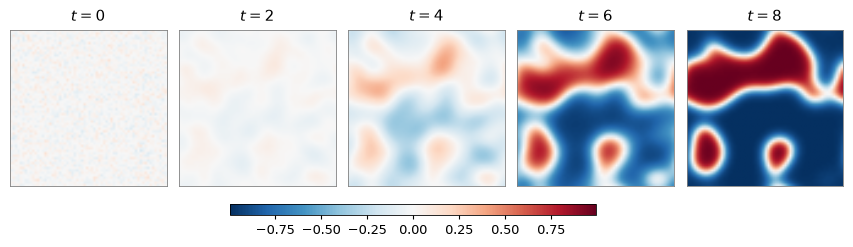

In [3]:
fig, paths = nb.plot_motion(
    clean, times, SIM['L'], n_frames=5,
    cmap='RdBu_r', symmetric=True,
    time_fmt='.0f',
    save_as=f'{EQ}_motion',
)
for p in paths:
    print('written:', p.split('/code/')[-1])

## 4. Design matrices

In [4]:
Lx = Ly = SIM['L']

data = {
    0.00: nb.regression_data(clean, times, EQ),
    NOISE: nb.regression_data(noisy, times, EQ),
}
print(f'{len(data[0.00][0])} interior snapshots')

ev = nb.JetEvaluator(clean, times, Lx, Ly, EQ)
ev.summary()

designs, fits = {}, {}
for key, cfg in BEST.items():
    f_snaps, ft_snaps, idx_sets, _ = data[key[0]]
    Theta, Ft, desc = nb.build_design(
        f_snaps, ft_snaps, idx_sets, Lx, Ly, cfg)
    designs[key] = (Theta, Ft, desc)
    fits[key] = nb.run_fit(Theta, Ft, cfg)
    print(f'{key[0] * 100:>3.0f}%  {key[1]:<4} {cfg["library"]:<15} '
          f'Theta {str(Theta.shape):<13} cond {np.linalg.cond(Theta):.2e}')

39 interior snapshots


Evaluation space: 119 jet monomials, 159,744 rows, 4 true active terms


  0%  eq   multigraph      Theta (3900, 20)    cond 2.68e+03


  0%  neq  pdefind         Theta (3900, 60)    cond 3.42e+03


  2%  eq   multigraph      Theta (3900, 20)    cond 4.04e+03


  2%  neq  pdefind         Theta (3900, 60)    cond 6.28e+03


## 5. Recovery with clean data

In [5]:
print('Ground truth:  f_t = 0.0225·Δf + f − f³')
print()
for group in ('eq', 'neq'):
    key = (0.00, group)
    nb.show_recovery(fits[key], designs[key][2], BEST[key], ev)
    print()

Ground truth:  f_t = 0.0225·Δf + f − f³

── Multigraph ──
   Multigraph · weak (IBP) · STRidge · spectral derivatives · m=12, p=6 · λ=1e-06, d_tol=0.1
   f_t = (+0.99513)f + (-0.99333)f³ + (+0.02241)Δf
   3 active terms · fp=0 fn=0 · EXACT RECOVERY
   E_coeff = 0.004785   max|Δc| = 0.00667

── PDE-FIND ──
   PDE-FIND · weak (IBP) · STRidge · spectral derivatives · m=12, p=6 · λ=1e-06, d_tol=0.1
   f_t = (+0.02244)f_yy + (+0.02239)f_xx + (+0.99511)f + (-0.99332)f³
   4 active terms · fp=0 fn=0 · EXACT RECOVERY
   E_coeff = 0.004806   max|Δc| = 0.00668



In [6]:
for group in ('eq', 'neq'):
    key = (0.00, group)
    print(nb.LIBRARY_LABEL[BEST[key]['library']] + ':')
    nb.coefficient_table(
        fits[key], designs[key][2], BEST[key], ev)
    print()

Multigraph:
term     recovered        true       error
──────────────────────────────────────────
f          0.99513     1.00000   -4.87e-03
f³        -0.99333    -1.00000    6.67e-03
f_xx       0.02241     0.02250   -8.98e-05
f_yy       0.02241     0.02250   -8.98e-05

PDE-FIND:
term     recovered        true       error
──────────────────────────────────────────
f          0.99511     1.00000   -4.89e-03
f³        -0.99332    -1.00000    6.68e-03
f_xx       0.02239     0.02250   -1.11e-04
f_yy       0.02244     0.02250   -6.47e-05



## 6. Recovery at 2 % noise

In [7]:
print('Ground truth:  f_t = 0.0225·Δf + f − f³')
print()
for group in ('eq', 'neq'):
    key = (NOISE, group)
    nb.show_recovery(fits[key], designs[key][2], BEST[key], ev)
    print()

Ground truth:  f_t = 0.0225·Δf + f − f³

── Multigraph ──
   Multigraph · weak (IBP) · RFE · spectral derivatives · m=12, p=6 · λ=0
   f_t = (+0.99519)f + (-0.99318)f³ + (+0.02238)Δf
   3 active terms · fp=0 fn=0 · EXACT RECOVERY
   E_coeff = 0.004809   max|Δc| = 0.00682

── PDE-FIND ──
   PDE-FIND · weak (IBP) · RFE · spectral derivatives · m=12, p=6 · λ=0
   f_t = (+0.02240)f_yy + (+0.02236)f_xx + (+0.99517)f + (-0.99317)f³
   4 active terms · fp=0 fn=0 · EXACT RECOVERY
   E_coeff = 0.004817   max|Δc| = 0.00683



In [8]:
for group in ('eq', 'neq'):
    key = (NOISE, group)
    print(nb.LIBRARY_LABEL[BEST[key]['library']] + ':')
    nb.coefficient_table(
        fits[key], designs[key][2], BEST[key], ev)
    print()

Multigraph:
term     recovered        true       error
──────────────────────────────────────────
f          0.99519     1.00000   -4.81e-03
f³        -0.99318    -1.00000    6.82e-03
f_xx       0.02238     0.02250   -1.24e-04
f_yy       0.02238     0.02250   -1.24e-04

PDE-FIND:
term     recovered        true       error
──────────────────────────────────────────
f          0.99517     1.00000   -4.83e-03
f³        -0.99317    -1.00000    6.83e-03
f_xx       0.02236     0.02250   -1.44e-04
f_yy       0.02240     0.02250   -1.01e-04

